# USPTO Innovator Collaboration Network

This project uses USPTO patent application data to build a small inventor collaboration network.

We will:

- start with one inventor
- retrieve some of that inventor's patent applications
- identify co-inventors
- continue outward through the co-inventor network
- build and visualize the network with NetworkX

In this network:

- inventors are nodes
- two inventors are connected when they appear on the same patent application
- repeated collaborations increase the weight of the edge

This project is intentionally parallel to the OpenAlex Researcher Collaboration Network project.


## 1. Setup

USPTO Open Data Portal access requires an API key.

Store the key in a `config.yml` file:

```yaml
api_key: YOUR_USPTO_API_KEY
```

Do not commit `config.yml` to a public repository.


In [1]:
import requests
import yaml
import json
import networkx as nx
import matplotlib.pyplot as plt
import time

from collections import deque
from itertools import combinations

with open("config.yml", "r") as f:
    config = yaml.safe_load(f)

API_KEY = config["uspto_api_key"]

URL = "https://api.uspto.gov/api/v1/patent/applications/search"

HEADERS = {
    "X-API-KEY": API_KEY,
    "Accept": "application/json"
}


## 2. Choose an Inventor and Network Size

We will use Mahdi Zamani as the example because the USPTO search returns a useful set of patent applications and co-inventors.

The two limits keep the network small enough to inspect and visualize.


In [2]:
SEED_INVENTOR = "Jennifer Doudna"

MAX_INVENTORS = 20
MAX_APPLICATIONS_PER_INVENTOR = 5


## 3. Search USPTO for an Inventor

The USPTO search syntax lets us search specifically within the inventor-name field.

For example, a search for `Mahdi Zamani` becomes:

```text
applicationMetaData.inventorBag.inventorNameText:Mahdi
AND
applicationMetaData.inventorBag.inventorNameText:Zamani
```

The helper below constructs that query and returns a small number of the most recent matching applications.


In [3]:
def get_applications(inventor_name):

    # Ignore middle initials when constructing the search.
    name_parts = [
        part
        for part in inventor_name.replace(".", "").split()
        if len(part) > 1
    ]

    query = " AND ".join(
        f"applicationMetaData.inventorBag.inventorNameText:{part}"
        for part in name_parts
    )

    response = requests.get(
        URL,
        headers=HEADERS,
        params={
            "q": query,
            "limit": 100
        }
    )

    time.sleep(0.5)
    response.raise_for_status()

    records = response.json()["patentFileWrapperDataBag"]

    records = sorted(
        records,
        key=lambda record: record.get(
            "applicationMetaData", {}
        ).get("filingDate", ""),
        reverse=True
    )

    return records[:MAX_APPLICATIONS_PER_INVENTOR]


We also use one small function to make capitalization and spacing more consistent.


In [4]:
def clean_name(name):
    return " ".join(name.split()).title()


## 4. Look at the Starting Inventor's Applications

Before building a network, inspect the data returned for the starting inventor.


In [5]:
applications = get_applications(SEED_INVENTOR)

print("Applications returned:", len(applications))

for record in applications:
    metadata = record.get("applicationMetaData", {})

    print()
    print(metadata.get("inventionTitle"))

    inventors = [
        person.get("inventorNameText")
        for person in metadata.get("inventorBag", [])
        if person.get("inventorNameText")
    ]

    print(inventors)


Applications returned: 5

COMPOSITIONS AND METHODS FOR DELIVERY OF MOLECULAR CARGO TO CELLS
['KEVIN WASKO', 'JENNIFER A. DOUDNA']

COMPOSITIONS AND METHODS FOR DELIVERING MOLECULAR CARGO TO CELLS
['WAYNE NGO', 'JENNIFER A. DOUDNA']

Vivo gene editing of Tau locus via liponanoparticle delivery
['Niren Murthy', 'Andrea Gomez', 'Jennifer Doudna', 'Rohit Sharma', 'Yung Yi Hsiao', 'Fyodor Urnov', 'Elizabeth Stahl', 'Viviana Salinas-Rios']

Compositions and Methods for Targeted Delivery of CRISPR-CAS Effector Polypeptides and Transgenes
['Jennifer A. Doudna', 'Jennifer Hamilton', 'Connor Tsuchida']

COMPOSITIONS AND METHODS FOR DELIVERING MOLECULAR CARGO TO CELLS
['Wayne Ngo', 'Jennifer A. Doudna']


The `inventorBag` contains inventor records. Each inventor record includes an `inventorNameText` field.

Those names give us the relationships needed to construct the network.


## 5. Build the Co-inventor Network

We will expand outward from the starting inventor using a breadth-first search.

The process is similar to the OpenAlex researcher-network project:

1. Start with one inventor.
2. Retrieve some of that inventor's applications.
3. Add the other inventors on those applications.
4. Put newly discovered inventors into a queue.
5. Search those inventors in turn.
6. Stop when the graph reaches `MAX_INVENTORS`.

Everyone listed on the same application is treated as a collaborator.


In [6]:
G = nx.Graph()

SEED_INVENTOR = clean_name(SEED_INVENTOR)

G.add_node(SEED_INVENTOR)

frontier = deque([SEED_INVENTOR])
searched = set()


Now expand the network.

The `combinations()` function creates every pair of inventors on an application. For example, if an application contains Alice, Bob, and Carol, it creates:

```text
Alice -- Bob
Alice -- Carol
Bob   -- Carol
```


In [7]:
while frontier and G.number_of_nodes() < MAX_INVENTORS:

    inventor = frontier.popleft()

    if inventor in searched:
        continue

    print(
        f"Searching {inventor} "
        f"({G.number_of_nodes()} inventors so far)"
    )

    searched.add(inventor)

    applications = get_applications(inventor)

    for record in applications:

        metadata = record.get("applicationMetaData", {})

        inventors = [
            clean_name(person["inventorNameText"])
            for person in metadata.get("inventorBag", [])
            if person.get("inventorNameText")
        ]

        # Remove duplicate names while keeping their order.
        inventors = list(dict.fromkeys(inventors))

        # Make sure the inventor we searched for is actually
        # represented in the returned inventor list.
        searched_parts = inventor.replace(".", "").upper().split()

        if len(searched_parts) < 2:
            continue

        searched_key = (
            searched_parts[0],
            searched_parts[-1]
        )

        matching_names = []

        for name in inventors:
            parts = name.replace(".", "").upper().split()

            if (
                len(parts) >= 2
                and (parts[0], parts[-1]) == searched_key
            ):
                matching_names.append(name)

        if not matching_names:
            continue

        # Add inventors from this application.
        for name in inventors:

            if name not in G:

                if G.number_of_nodes() >= MAX_INVENTORS:
                    continue

                G.add_node(name)

                if name not in searched:
                    frontier.append(name)

        # Connect every inventor pair already included
        # in our bounded graph.
        graph_inventors = [
            name
            for name in inventors
            if name in G
        ]

        for inventor_a, inventor_b in combinations(
            graph_inventors,
            2
        ):

            if G.has_edge(inventor_a, inventor_b):
                G[inventor_a][inventor_b]["weight"] += 1
            else:
                G.add_edge(
                    inventor_a,
                    inventor_b,
                    weight=1
                )


Searching Jennifer Doudna (1 inventors so far)
Searching Kevin Wasko (13 inventors so far)
Searching Jennifer A. Doudna (13 inventors so far)
Searching Wayne Ngo (13 inventors so far)
Searching Niren Murthy (15 inventors so far)


## 6. Inspect the Network

The network is deliberately small. `MAX_INVENTORS = 20` is a teaching limit, not a statement about how many collaborators the inventor actually has.


In [8]:
print()
print("Finished!")
print("Inventors:", G.number_of_nodes())
print("Collaborations:", G.number_of_edges())
print("Inventors searched:", len(searched))
print("Isolated inventors:", len(list(nx.isolates(G))))

if G.number_of_nodes():
    print("Connected:", nx.is_connected(G))



Finished!
Inventors: 20
Collaborations: 50
Inventors searched: 5
Isolated inventors: 0
Connected: True


Look at a few nodes and edges.


In [9]:
list(G.nodes())[:10]


['Jennifer Doudna',
 'Kevin Wasko',
 'Jennifer A. Doudna',
 'Wayne Ngo',
 'Niren Murthy',
 'Andrea Gomez',
 'Rohit Sharma',
 'Yung Yi Hsiao',
 'Fyodor Urnov',
 'Elizabeth Stahl']

In [10]:
list(G.edges(data=True))[:10]


[('Jennifer Doudna', 'Niren Murthy', {'weight': 3}),
 ('Jennifer Doudna', 'Andrea Gomez', {'weight': 3}),
 ('Jennifer Doudna', 'Rohit Sharma', {'weight': 3}),
 ('Jennifer Doudna', 'Yung Yi Hsiao', {'weight': 3}),
 ('Jennifer Doudna', 'Fyodor Urnov', {'weight': 3}),
 ('Jennifer Doudna', 'Elizabeth Stahl', {'weight': 3}),
 ('Jennifer Doudna', 'Viviana Salinas-Rios', {'weight': 3}),
 ('Kevin Wasko', 'Jennifer A. Doudna', {'weight': 4}),
 ('Jennifer A. Doudna', 'Wayne Ngo', {'weight': 9}),
 ('Jennifer A. Doudna', 'Jennifer Hamilton', {'weight': 2})]

The `weight` on an edge records how many retrieved applications contained that inventor pair.


## 7. Visualize the Network

We use the same NetworkX spring layout used in the OpenAlex researcher-network project.


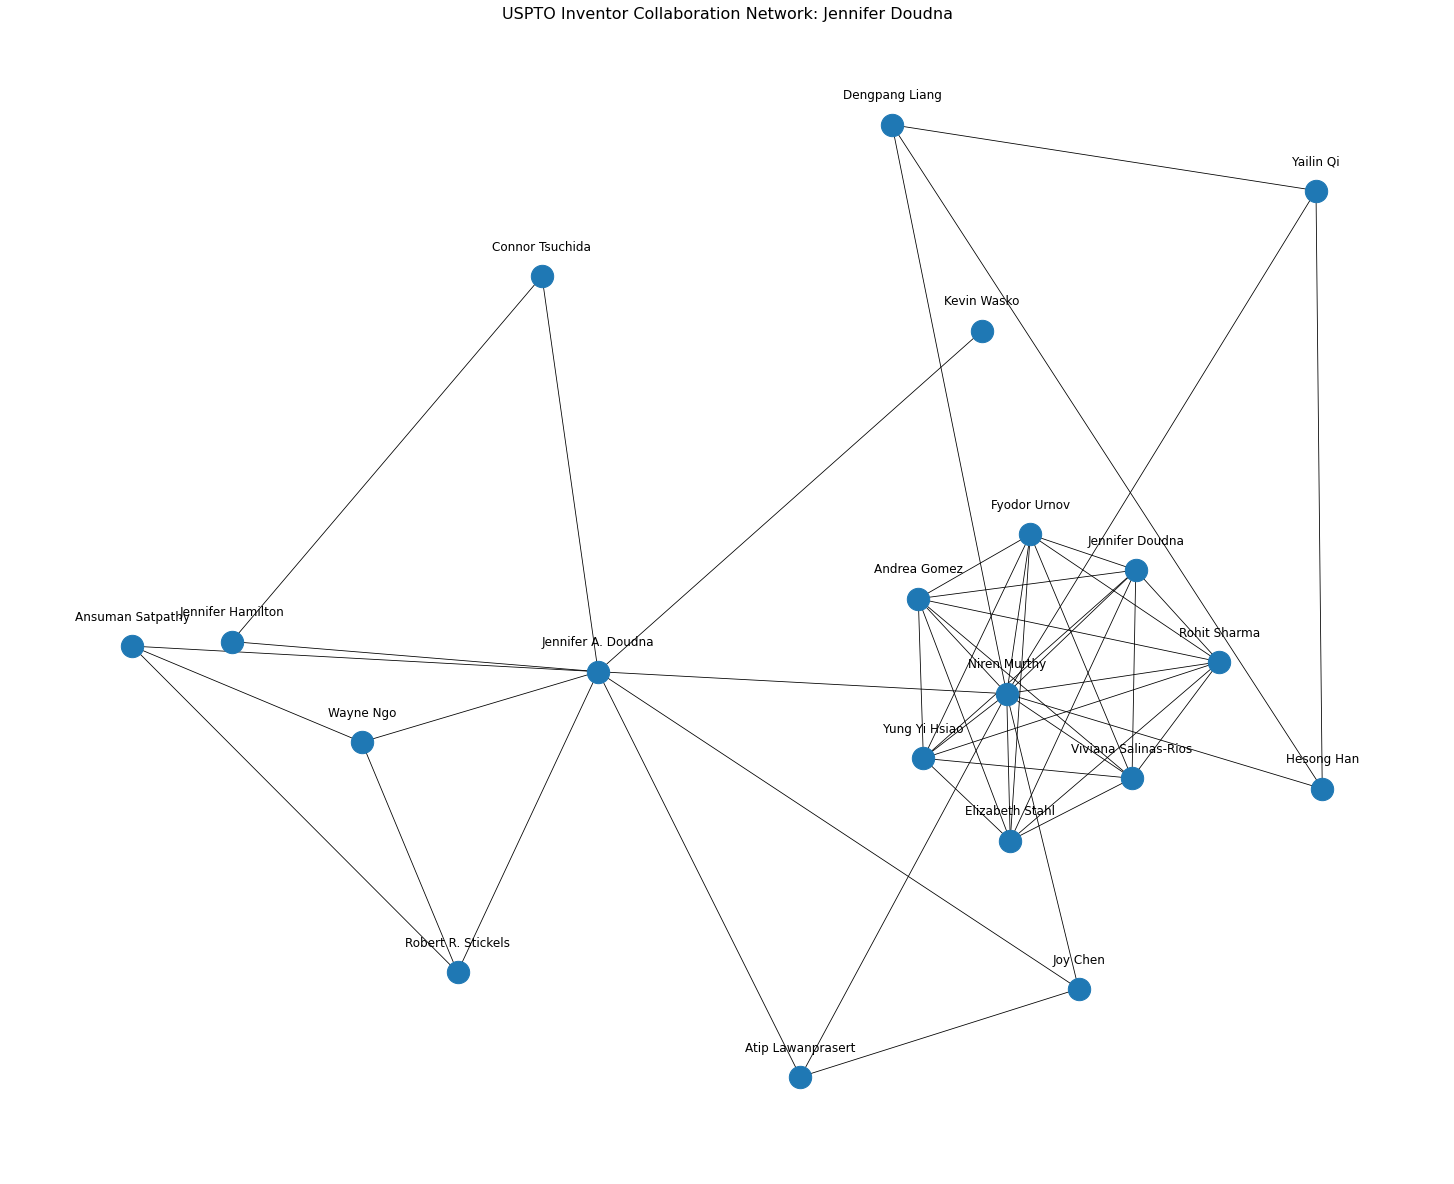

In [11]:
plt.figure(figsize=(20, 16))

pos = nx.spring_layout(
    G,
    seed=42,
    k=2.5,
    iterations=100
)

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=500,
    width=0.8
)

label_pos = {
    node: (x, y + 0.04)
    for node, (x, y) in pos.items()
}

nx.draw_networkx_labels(
    G,
    label_pos,
    font_size=12
)

plt.title(
    f"USPTO Inventor Collaboration Network: {SEED_INVENTOR}",
    fontsize=16
)

plt.axis("off")
plt.show()


## 8. Interpret the Network

Some questions to consider:

- Which inventors appear highly connected?
- Which groups of inventors appear together?
- Which inventor pairs have larger edge weights?
- How would the graph change if we retrieved more applications?
- What assignees or CPC classifications might add useful context?

The graph represents a sample of relationships found in the records we retrieved. It is not a complete map of an inventor's collaboration history.


## 9. A Note About Inventor Names

This is an important difference between the USPTO and OpenAlex projects.

OpenAlex provides persistent author identifiers. Here we are using inventor names.

Names may differ across patent records because of middle initials, punctuation, spelling, name order, or other variations. Different people can also share the same name.

For this teaching example, we use a simple first-name/last-name comparison when checking search results. A research project would require more careful inventor identity validation.


## 10. Try Another Inventor

Change:

```python
SEED_INVENTOR = "Mahdi Zamani"
```

to another inventor who interests you.

You can also experiment with:

```python
MAX_INVENTORS = 20
MAX_APPLICATIONS_PER_INVENTOR = 5
```

Start with small values. Larger values require more API requests and can quickly create graphs that are difficult to visualize.


## 11. Researcher Networks and Innovator Networks

This project uses patent inventorship to construct an innovator collaboration network.

The parallel OpenAlex project uses publication authorship to construct a researcher collaboration network.

The notebooks intentionally remain separate. Connecting researcher and inventor identities across OpenAlex and USPTO is a substantially more complicated problem and is better treated as a research project.
